<a href="https://colab.research.google.com/github/ivansuarez-AU/MAI510_M2_Assignment_2_2/blob/main/MAI510_M2_Assignment_2_2_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAI 510 • Module 2 • Assignment 2.2
## What Regularisation Is Worth — and a Working Web Application
**Run cells from top to bottom.** The 4 models use the same data split and training settings; only batch normalization and dropout change.
**Instructor mode:** `DEMO_MODE=True` runs a short illustrative experiment. **Student submissions:** `DEMO_MODE=False` for complete training, real photos, and original written explanations.

**What you will produce:** a four-model comparison table, charts, a saved best model, Flask app files, a real-photo evaluation table, and a named Word report.

**Important:** Fashion-MNIST images are 28×28 grayscale and centered. Real photos have a different distribution; do not expect similar accuracy.

## Lab 0 — Enter student name and choose demonstration mode

In [1]:
import re, os, csv, json, io, zipfile, shutil, random, sys, subprocess
from pathlib import Path
print('MAI 510 — Module 2 / Assignment 2.2')
STUDENT_NAME = input('Enter your FULL name: ').strip()
while not STUDENT_NAME or STUDENT_NAME.lower() in {'your name','student name','name'}:
    STUDENT_NAME = input('Full name required: ').strip()
SAFE_NAME = re.sub(r'[^a-zA-Z0-9]+','_',STUDENT_NAME).strip('_')
COURSE = 'MAI 510 — Deep Learning'
DEMO_MODE = True  # CHANGE TO False for graded student work
SEED = 42
random.seed(SEED)
OUT = Path(f'MAI510_M2_A22_{SAFE_NAME}')
OUT.mkdir(exist_ok=True)
print('Student:',STUDENT_NAME,'| Demonstration mode:',DEMO_MODE,'| Folder:',OUT)

MAI 510 — Module 2 / Assignment 2.2
Enter your FULL name: Ivan Suarez
Student: Ivan Suarez | Demonstration mode: True | Folder: MAI510_M2_A22_Ivan_Suarez


## Lab 1 — Load Fashion-MNIST and create a fair train/validation/test split

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train: (10200, 28, 28, 1) validation: (2250, 28, 28, 1) held-out test: (10000, 28, 28, 1)


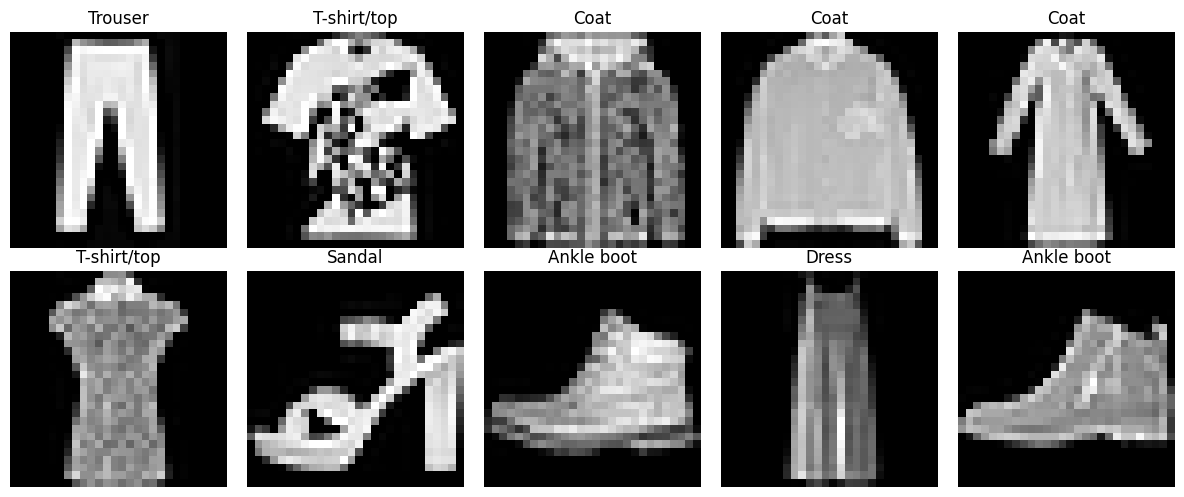

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from PIL import Image, ImageOps
np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
CLASS_NAMES=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
(x_train_all,y_train_all),(x_test,y_test)=keras.datasets.fashion_mnist.load_data()
x_train_all=(x_train_all.astype('float32')/255.0)[...,None]
x_test=(x_test.astype('float32')/255.0)[...,None]
x_train,x_val,y_train,y_val=train_test_split(x_train_all,y_train_all,test_size=0.15,random_state=SEED,stratify=y_train_all)
if DEMO_MODE:
    # Stratified subset; same for all four architectures.
    from sklearn.model_selection import train_test_split as split
    _,x_train,y_unused,y_train=split(x_train,y_train,test_size=0.20,random_state=SEED,stratify=y_train)
    _,x_val,v_unused,y_val=split(x_val,y_val,test_size=0.25,random_state=SEED,stratify=y_val)
print('train:',x_train.shape,'validation:',x_val.shape,'held-out test:',x_test.shape)
fig,axs=plt.subplots(2,5,figsize=(12,5))
for i,ax in enumerate(axs.flat): ax.imshow(x_train[i,:,:,0],cmap='gray'); ax.set_title(CLASS_NAMES[int(y_train[i])]);ax.axis('off')
plt.tight_layout(); plt.show()

## Lab 2 — Define exactly four CNN variants
Baseline: BN + Dropout. Variants: no BN, no Dropout, neither. Architecture and other settings remain fixed.

In [3]:
CONFIGS=[('Baseline: BN + Dropout',True,True),('Without BN',False,True),('Without Dropout',True,False),('Without Either',False,False)]
BATCH_SIZE=128
MAX_EPOCHS=3 if DEMO_MODE else 20
PATIENCE=2 if DEMO_MODE else 4

def build_model(use_bn=True,use_dropout=True):
    tf.keras.utils.set_random_seed(SEED)
    inp=keras.Input(shape=(28,28,1))
    z=layers.Conv2D(32,3,padding='same',use_bias=not use_bn)(inp)
    if use_bn: z=layers.BatchNormalization()(z)
    z=layers.Activation('relu')(z)
    z=layers.MaxPooling2D()(z)
    z=layers.Conv2D(64,3,padding='same',use_bias=not use_bn)(z)
    if use_bn: z=layers.BatchNormalization()(z)
    z=layers.Activation('relu')(z)
    z=layers.MaxPooling2D()(z)
    z=layers.Flatten()(z)
    z=layers.Dense(64,activation='relu')(z)
    if use_dropout: z=layers.Dropout(0.30)(z)
    out=layers.Dense(10,activation='softmax')(z)
    model=keras.Model(inp,out)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return model
print('Variants:',[item[0] for item in CONFIGS]);build_model().summary()

Variants: ['Baseline: BN + Dropout', 'Without BN', 'Without Dropout', 'Without Either']


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,522 (861.41 KB)

 Trainable params: 220,330 (860.66 KB)

 Non-trainable params: 192 (768.00 B)

## Lab 3 — Train the four models
Watch for overfitting (training accuracy improves but validation performance stops improving). We restore the best validation-loss weights. Results are experimental, not guaranteed.

In [4]:
histories={};results=[];saved_paths={}
for name,use_bn,use_dropout in CONFIGS:
    print('\nTRAINING:',name)
    model=build_model(use_bn,use_dropout)
    callback=keras.callbacks.EarlyStopping(monitor='val_loss',patience=PATIENCE,restore_best_weights=True)
    history=model.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=MAX_EPOCHS,batch_size=BATCH_SIZE,callbacks=[callback],verbose=2)
    histories[name]=history.history
    test_loss,test_acc=model.evaluate(x_test,y_test,verbose=0)
    # Gap uses the final recorded epoch's training and validation accuracy.
    train_acc=float(history.history['accuracy'][-1]);val_acc=float(history.history['val_accuracy'][-1])
    gap=train_acc-val_acc
    path=OUT/('model_'+re.sub(r'[^a-z0-9]+','_',name.lower()).strip('_')+'.keras')
    model.save(path);saved_paths[name]=path
    results.append({'model':name,'batch_norm':use_bn,'dropout':use_dropout,'epochs':len(history.history['loss']),'train_accuracy_final':train_acc,'val_accuracy_final':val_acc,'train_minus_val_gap_pp':100*gap,'test_accuracy':float(test_acc),'test_loss':float(test_loss),'parameters':model.count_params()})
    print('test acc:',round(float(test_acc),4),'gap (percentage points):',round(100*gap,2))
comparison=pd.DataFrame(results).sort_values('test_accuracy',ascending=False).reset_index(drop=True)
display(comparison.round(4));comparison.to_csv(OUT/'four_model_comparison.csv',index=False)


TRAINING: Baseline: BN + Dropout
Epoch 1/3
80/80 - 21s - 259ms/step - accuracy: 0.6390 - loss: 1.0484 - val_accuracy: 0.2076 - val_loss: 2.0751
Epoch 2/3
80/80 - 19s - 238ms/step - accuracy: 0.7777 - loss: 0.6255 - val_accuracy: 0.2644 - val_loss: 1.9262
Epoch 3/3
80/80 - 19s - 240ms/step - accuracy: 0.8124 - loss: 0.5237 - val_accuracy: 0.4929 - val_loss: 1.6143
test acc: 0.4807 gap (percentage points): 31.95

TRAINING: Without BN
Epoch 1/3
80/80 - 13s - 164ms/step - accuracy: 0.6224 - loss: 1.0526 - val_accuracy: 0.7751 - val_loss: 0.5723
Epoch 2/3
80/80 - 21s - 260ms/step - accuracy: 0.7720 - loss: 0.6143 - val_accuracy: 0.8076 - val_loss: 0.4983
Epoch 3/3
80/80 - 12s - 150ms/step - accuracy: 0.8030 - loss: 0.5290 - val_accuracy: 0.8329 - val_loss: 0.4444
test acc: 0.8174 gap (percentage points): -2.98

TRAINING: Without Dropout
Epoch 1/3
80/80 - 23s - 289ms/step - accuracy: 0.7439 - loss: 0.7371 - val_accuracy: 0.2462 - val_loss: 2.1161
Epoch 2/3
80/80 - 17s - 212ms/step - accurac

,model,batch_norm,dropout,epochs,train_accuracy_final,val_accuracy_final,train_minus_val_gap_pp,test_accuracy,test_loss,parameters
0,Without Either,False,False,3,0.8375,0.8609,-2.3438,0.8421,0.4356,220234
1,Without BN,False,True,3,0.8030,0.8329,-2.9850,0.8174,0.4811,220234
2,Baseline: BN + Dropout,True,True,3,0.8124,0.4929,31.9464,0.4807,1.6217,220522
3,Without Dropout,True,False,3,0.8754,0.2858,58.9614,0.2868,2.0859,220522


## Lab 4 — Compare learning curves and regularization effects
**Discuss:** Did batch normalization or dropout improve held-out test accuracy? Did either reduce the training–validation gap? A smaller gap alone does not guarantee a better model.

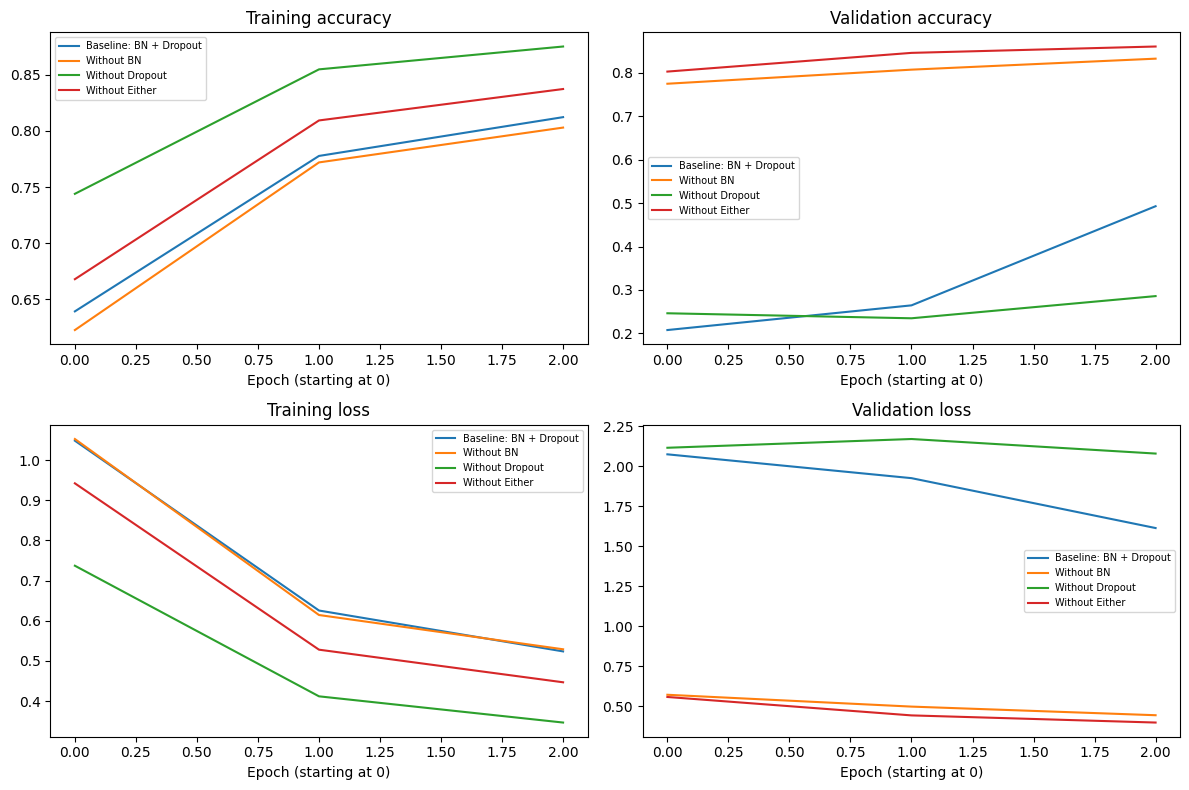

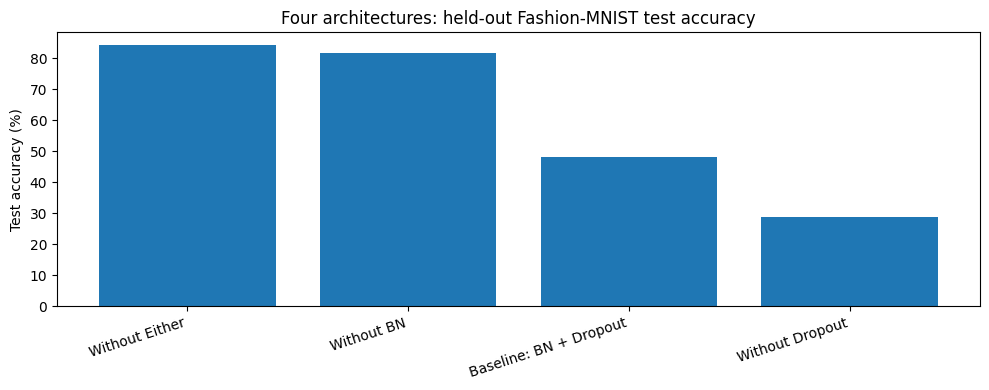

Report effects as measured differences in percentage points; attribution is limited because architectures can interact and one run is noisy.


In [5]:
fig,axs=plt.subplots(2,2,figsize=(12,8))
for name,h in histories.items():
    axs[0,0].plot(h['accuracy'],label=name);axs[0,1].plot(h['val_accuracy'],label=name)
    axs[1,0].plot(h['loss'],label=name);axs[1,1].plot(h['val_loss'],label=name)
for ax,title in zip(axs.flat,['Training accuracy','Validation accuracy','Training loss','Validation loss']): ax.set_title(title);ax.set_xlabel('Epoch (starting at 0)');ax.legend(fontsize=7)
plt.tight_layout();plt.savefig(OUT/'four_model_training_curves.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(10,4));bars=ax.bar(comparison['model'],comparison['test_accuracy']*100)
ax.set_ylabel('Test accuracy (%)');ax.set_title('Four architectures: held-out Fashion-MNIST test accuracy')
plt.xticks(rotation=18,ha='right');plt.tight_layout();plt.savefig(OUT/'four_model_test_accuracy.png',dpi=160);plt.show()
print('Report effects as measured differences in percentage points; attribution is limited because architectures can interact and one run is noisy.')

## Lab 5 — Select and save the model for deployment
The choice below uses test accuracy to match the assignment. For rigorous production evaluation, choose with validation data and reserve test data for a final independent assessment.

In [6]:
BEST_NAME=str(comparison.iloc[0]['model'])
BEST_PATH=saved_paths[BEST_NAME]
shutil.copy2(BEST_PATH,OUT/'best_model.keras')
BEST_MODEL=keras.models.load_model(OUT/'best_model.keras')
print('Top test accuracy:',BEST_NAME,'|',f"{comparison.iloc[0]['test_accuracy']:.2%}")
print('Saved:',OUT/'best_model.keras')

Top test accuracy: Without Either | 84.21%
Saved: MAI510_M2_A22_Ivan_Suarez/best_model.keras


## Lab 6 — Create the Flask web application files
The same preprocessing is used in the app and in the photo evaluation. This does not solve the Fashion-MNIST/real-photo distribution gap.
Run the following cell to create `app.py` and `requirements.txt`.

In [7]:
APP_SOURCE = '"""MAI 510 Assignment 2.2 – Flask clothing classifier.\nUsage: python app.py   (best_model.keras must be in the same folder)\n"""\nimport os, io\nimport numpy as np\nfrom PIL import Image, ImageOps, UnidentifiedImageError\nfrom flask import Flask, request, render_template_string\nfrom tensorflow import keras\n\napp = Flask(__name__)\napp.config[\'MAX_CONTENT_LENGTH\'] = 5 * 1024 * 1024\nLABELS=[\'T-shirt/top\',\'Trouser\',\'Pullover\',\'Dress\',\'Coat\',\'Sandal\',\'Shirt\',\'Sneaker\',\'Bag\',\'Ankle boot\']\nMODEL_PATH=os.environ.get(\'MODEL_PATH\',\'best_model.keras\')\nmodel=keras.models.load_model(MODEL_PATH)\nPAGE="""<!doctype html><html><head><meta charset=\'utf-8\'><title>MAI 510 • Clothing Recogniser</title>\n<style>body{font-family:Arial,sans-serif;max-width:650px;margin:45px auto;padding:0 20px;color:#162b45}header{border-bottom:3px solid #107b92;padding-bottom:12px}main{background:#f4f8fa;padding:26px;border-radius:12px;margin-top:20px}button{background:#107b92;color:white;padding:10px 22px;border:0;border-radius:6px;cursor:pointer}.warn{color:#864d15}</style></head><body>\n<header><h1>Clothing Recognition</h1><p>MAI 510 — Assignment 2.2 • CNN demonstration</p></header>\n<main><form method=\'post\' enctype=\'multipart/form-data\'><label>Upload JPG or PNG of one clothing item:</label><p><input type=\'file\' name=\'image\' accept=\'.jpg,.jpeg,.png\' required></p><button type=\'submit\'>Classify image</button></form>\n{% if error %}<p class=\'warn\'>{{error}}</p>{% endif %}\n{% if prediction %}<h2>Prediction: {{prediction}}</h2><p>Model softmax score: {{confidence}}%</p>{% endif %}\n<p class=\'warn\'>Trained on Fashion-MNIST (28×28 grayscale, centered garment). Real photographs may perform much worse; score is not a calibrated probability.</p></main></body></html>"""\n\ndef preprocess(raw):\n    image=Image.open(io.BytesIO(raw)).convert(\'L\')\n    image=ImageOps.fit(image,(28,28),method=Image.Resampling.LANCZOS)\n    pix=np.asarray(image,dtype=np.float32)\n    # Fashion-MNIST expects a bright garment against dark background.\n    # This coarse heuristic is a teaching baseline, not reliable segmentation.\n    corners=np.r_[pix[:4,:4].ravel(),pix[:4,-4:].ravel(),pix[-4:,:4].ravel(),pix[-4:,-4:].ravel()]\n    if float(corners.mean())>127: pix=255-pix\n    return (pix/255.0).reshape(1,28,28,1)\n\n@app.route(\'/\',methods=[\'GET\',\'POST\'])\ndef index():\n    if request.method==\'GET\': return render_template_string(PAGE,prediction=None,error=None)\n    item=request.files.get(\'image\')\n    if item is None or not item.filename: return render_template_string(PAGE,error=\'Choose an image.\',prediction=None)\n    if not item.filename.lower().endswith((\'.png\',\'.jpg\',\'.jpeg\')):\n        return render_template_string(PAGE,error=\'Only PNG/JPG accepted.\',prediction=None)\n    try:\n        raw=item.read()\n        if not raw or len(raw)>5*1024*1024: raise ValueError(\'Image is empty or too large (max 5 MB).\')\n        x=preprocess(raw)\n        probs=model.predict(x,verbose=0)[0]\n        return render_template_string(PAGE,prediction=LABELS[int(np.argmax(probs))],confidence=f\'{100*float(np.max(probs)):.1f}\',error=None)\n    except (UnidentifiedImageError,OSError,ValueError) as exc:\n        return render_template_string(PAGE,error=f\'Cannot process image: {exc}\',prediction=None)\n\nif __name__==\'__main__\':\n    app.run(host=\'127.0.0.1\',port=int(os.environ.get(\'PORT\',\'5000\')),debug=False)\n'
(OUT/'app.py').write_text(APP_SOURCE)
(OUT/'requirements.txt').write_text('tensorflow>=2.16,<3\nflask>=3,<4\npillow>=10\nnumpy>=1.26\n')
print('Created app.py and requirements.txt')

Created app.py and requirements.txt


## Lab 7 — Verify Flask endpoint inside Colab (no external hosting required)
The test client proves the upload route works. It does not create a public URL. For an actual browser application, run app.py locally with best_model.keras and dependencies installed.

In [8]:
import importlib.util
spec=importlib.util.spec_from_file_location('clothing_app',str((OUT/'app.py').resolve()))
module=importlib.util.module_from_spec(spec)
old=os.getcwd()
try:
    os.chdir(OUT)
    spec.loader.exec_module(module)
    sample=(x_test[0,:,:,0]*255).astype('uint8')
    buf=io.BytesIO();Image.fromarray(sample).save(buf,format='PNG');buf.seek(0)
    with module.app.test_client() as client:
        response=client.post('/',data={'image':(buf,'sample.png')},content_type='multipart/form-data')
        print('HTTP status:',response.status_code,'| Prediction shown:',b'Prediction:' in response.data)
        assert response.status_code==200 and b'Prediction:' in response.data
finally:
    os.chdir(old)
print('Flask route test passed. Launch locally as documented in the instructor guide.')

HTTP status: 200 | Prediction shown: True
Flask route test passed. Launch locally as documented in the instructor guide.


## Lab 8 — Upload real clothing photographs (at least 10)
Create ONE `.zip` containing **at least 10 different photos** (not Fashion-MNIST). Label them with folder names `Sneaker/photo.jpg` or filename prefixes `Sneaker__photo.jpg`. Supported categories are exactly the 10 Fashion-MNIST classes. Only use images you have permission to use.
Instructor may skip upload during a short demo; student final submission must not skip.

In [9]:
from google.colab import files
print('Upload a ZIP of labeled real clothing images (or cancel for a short instructor demo).')
uploaded=files.upload()
PHOTO_DIR=OUT/'real_photos';PHOTO_DIR.mkdir(exist_ok=True)
if uploaded:
    zip_name=next(iter(uploaded))
    if not zip_name.lower().endswith('.zip'): raise ValueError('Please upload a ZIP file of JPG/PNG images.')
    with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
        for member in z.infolist():
            file_path=Path(member.filename)
            if member.is_dir() or file_path.suffix.lower() not in {'.jpg','.jpeg','.png'}:continue
            if file_path.is_absolute() or '..' in file_path.parts: continue
            # flatten with folder name preserved in filename
            dst=PHOTO_DIR/('__'.join(file_path.parts))
            dst.write_bytes(z.read(member))
print('Images received:',len(list(PHOTO_DIR.iterdir())))

Upload a ZIP of labeled real clothing images (or cancel for a short instructor demo).


Images received: 0


## Lab 9 — Evaluate real photos and compare their accuracy with test-set accuracy
For fairness, do not change labels after seeing the predictions. Incorrect or unsupported images should be documented instead of discarded.

In [10]:
def get_label(filename):
    prefix=filename.split('__')[0].lower().strip()
    normalized={re.sub(r'[^a-z0-9]+','',n.lower()):n for n in CLASS_NAMES}
    return normalized.get(re.sub(r'[^a-z0-9]+','',prefix))
photo_rows=[]
for p in sorted(PHOTO_DIR.iterdir()):
    if p.suffix.lower() not in {'.png','.jpg','.jpeg'}: continue
    label=get_label(p.name)
    if label is None:
        print('Skipped unrecognized class label:',p.name);continue
    try:
        arr=module.preprocess(p.read_bytes());probs=BEST_MODEL.predict(arr,verbose=0)[0]
        pred=CLASS_NAMES[int(np.argmax(probs))]
        photo_rows.append({'filename':p.name,'true_class':label,'predicted_class':pred,'confidence':round(float(probs.max()),4),'correct':pred==label})
    except Exception as exc: print('Photo processing error:',p.name,exc)
photo_results=pd.DataFrame(photo_rows,columns=['filename','true_class','predicted_class','confidence','correct'])
photo_results.to_csv(OUT/'real_photo_results.csv',index=False)
if len(photo_results):
    photo_accuracy=float(photo_results['correct'].mean())
    test_accuracy=float(comparison.iloc[0]['test_accuracy'])
    print('Real photo images:',len(photo_results),'correct:',int(photo_results['correct'].sum()))
    print(f'Real photo accuracy: {photo_accuracy:.1%}; Fashion-MNIST test accuracy: {test_accuracy:.1%}; difference: {(test_accuracy-photo_accuracy)*100:.1f} percentage points')
    display(photo_results)
else:
    photo_accuracy=None
    print('No valid labeled photos processed. Upload at least ten for the final assignment.')

No valid labeled photos processed. Upload at least ten for the final assignment.


## Lab 10 — Write YOUR evidence-based analysis
Provide your own text below. You may leave it blank during a classroom demonstration, but final export will enforce completeness.
**Required:** state what BN and dropout were measurably worth, explain the real-photo accuracy gap, and select ONE change most likely to close it.

In [11]:
REGULARIZATION_ANALYSIS = """"""  # Describe actual four-model numbers, interactions, and limits
REAL_PHOTO_ANALYSIS = """"""  # Compare test-set and >=10 real photographs; explain distribution shift
SINGLE_IMPROVEMENT = """"""  # ONE improvement and why you would test it
DEPLOYMENT_REFLECTION = """"""  # Flask experience, input preprocessing, limitations
print('Analysis sections are ready to edit. Re-run this cell after writing your explanations.')

Analysis sections are ready to edit. Re-run this cell after writing your explanations.


## Lab 11 — Export the named Word report + complete submission ZIP
**Students:** complete all four text responses and at least 10 images. **Instructor:** `ALLOW_DEMO_PLACEHOLDERS=True` may produce a clearly marked *non-submittable* demo package.

In [13]:
ALLOW_DEMO_PLACEHOLDERS = True # True only for instructor demonstrations
responses={'Regularization comparison':REGULARIZATION_ANALYSIS,'Real photo vs test accuracy':REAL_PHOTO_ANALYSIS,'Single proposed improvement':SINGLE_IMPROVEMENT,'Deployment reflection':DEPLOYMENT_REFLECTION}
missing=[k for k,v in responses.items() if not str(v).strip()]
if (missing or len(photo_results)<10 or DEMO_MODE) and not ALLOW_DEMO_PLACEHOLDERS:
    raise ValueError('Final export requires DEMO_MODE=False, >=10 labeled real photos, and all four written responses. Missing: '+', '.join(missing))
if missing:
    for k in missing:responses[k]='[INSTRUCTOR DEMONSTRATION PLACEHOLDER — NOT FOR STUDENT SUBMISSION]'
try:
    from docx import Document
    from docx.shared import Inches
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','-q','install','python-docx'])
    from docx import Document
    from docx.shared import Inches
report=Document(); report.add_heading('MAI 510 — Assignment 2.2',0)
report.add_paragraph('What Regularisation Is Worth, and a Working Web Application')
report.add_paragraph(f'Student: {STUDENT_NAME} | Mode: {"INSTRUCTOR DEMO (not for submission)" if DEMO_MODE else "STUDENT EXPERIMENT"}')
report.add_heading('Four-model comparison',level=1)
t=report.add_table(rows=1,cols=4);t.style='Light Shading Accent 1'
for c,v in zip(t.rows[0].cells,['Configuration','Test accuracy','Train–val gap (pp)','Epochs']):c.text=v
for _,r in comparison.iterrows():
    cells=t.add_row().cells
    for c,v in zip(cells,[str(r['model']),f"{r['test_accuracy']:.2%}",f"{r['train_minus_val_gap_pp']:.2f}",str(r['epochs'])]):c.text=v
report.add_paragraph('Gap = final recorded training accuracy minus final recorded validation accuracy in percentage points.')
report.add_heading('Deployment & real-photo evaluation',level=1)
report.add_paragraph(f"Selected model: {BEST_NAME}. Test accuracy: {float(comparison.iloc[0]['test_accuracy']):.2%}.")
report.add_paragraph(f"Labeled real photographs evaluated: {len(photo_results)}. Correct: {int(photo_results['correct'].sum()) if len(photo_results) else 0}. Real-photo accuracy: {photo_accuracy:.2%}" if photo_accuracy is not None else 'No labeled real photographs supplied.')
for heading,body in responses.items():report.add_heading(heading,level=2);report.add_paragraph(body)
for img in ['four_model_test_accuracy.png','four_model_training_curves.png']:
    if (OUT/img).exists():report.add_picture(str(OUT/img),width=Inches(5.7))
report.add_paragraph('Supporting CSV, Flask application source, model, and real-photo evidence are in the ZIP.')
report_path=OUT/f'{SAFE_NAME}_Assignment_2_2_Report.docx';report.save(report_path)
(OUT/'README_SUBMISSION.txt').write_text(f'MAI 510 - {STUDENT_NAME} - Assignment 2.2\nDownload executed ipynb separately; notebook is NOT inside this generated ZIP.\nMode: {"INSTRUCTOR DEMO — NOT FINAL" if DEMO_MODE else "STUDENT"}\nPhotos: {len(photo_results)}\n')
zip_path=Path(OUT.name+'_SUBMISSION.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file():z.write(p,arcname=str(p.relative_to(OUT.parent)))
print('Created report:',report_path,'| ZIP:',zip_path)
from google.colab import files
files.download(str(zip_path))

Created report: MAI510_M2_A22_Ivan_Suarez/Ivan_Suarez_Assignment_2_2_Report.docx | ZIP: MAI510_M2_A22_Ivan_Suarez_SUBMISSION.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Lab 12 — Final submission checklist
- [ ] Executed `.ipynb` downloaded separately (**File → Download → Download .ipynb**).
- [ ] Four models trained with the same splits/settings; comparison and learning curves included.
- [ ] Saved `best_model.keras` and working `app.py` + `requirements.txt`.
- [ ] At least **10 real photographs** with original true labels evaluated; results CSV included.
- [ ] One paragraph explaining the real-photo vs test-set accuracy gap and **one** proposed improvement.
- [ ] Instructor demonstration placeholders replaced; references/AI use disclosed if applicable.

### Local Flask launch (outside Colab)
1. Extract the generated ZIP and navigate to the folder containing `app.py` and `best_model.keras`.
2. Install: `python -m pip install -r requirements.txt`
3. Run: `python app.py`
4. In the browser visit `http://127.0.0.1:5000` and upload a JPG/PNG.

**Security:** Development server for local classroom use only; not a production-ready public deployment. Do not upload private/identifiable photographs.